This notebook will focus on initial data exploration, before any feature engineering or tokenization.

In [1]:
import pandas as pd 

df = pd.read_parquet("../data/processed/combined_filtered_dataset.parquet")
df.head()

,conversation_id,model,conversation,turn,language,openai_moderation,redacted
0,1e230e55efea4edab95db9cb87f6a9cb,vicuna-13b,[{'content': 'Beside OFAC's selective sanction...,6,English,"[{'categories': {'harassment': False, 'harassm...",False
1,0f623736051f4a48a506fd5933563cfd,vicuna-13b,[{'content': 'You are the text completion mode...,1,English,"[{'categories': {'harassment': False, 'harassm...",False
2,8ad66650dced4b728de1d14bb04657c1,vicuna-13b,[{'content': 'What is the type of the variable...,1,English,"[{'categories': {'harassment': False, 'harassm...",False
3,113d3ddd85874229a04a660bc629c2cc,vicuna-13b,"[{'content': 'summarise below transcript ""Stud...",1,English,"[{'categories': {'harassment': False, 'harassm...",False
4,64f322dcb69d43229bbd9785b7d90f1b,vicuna-13b,"[{'content': 'Buenas noches!', 'role': 'user'}...",8,Spanish,"[{'categories': {'harassment': False, 'harassm...",False


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 490712 entries, 0 to 490711
Data columns (total 7 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   conversation_id    490712 non-null  object
 1   model              490712 non-null  object
 2   conversation       490712 non-null  object
 3   turn               490712 non-null  int64 
 4   language           490712 non-null  object
 5   openai_moderation  490712 non-null  object
 6   redacted           490712 non-null  bool  
dtypes: bool(1), int64(1), object(5)
memory usage: 22.9+ MB


# conversation_id

The main thing to do for this variable is to check for duplicates

In [3]:
df["conversation_id"].duplicated().sum()

np.int64(0)

There are zero duplicated values, so conversation_id is guarnateed to be unique.

# model

Since this dataset only contains the instances from vicuna-13b, there is not any exploration. We can confirm that vicuna-13b is the only model.

In [4]:
df["model"].value_counts()

model
vicuna-13b    490712
Name: count, dtype: int64

# redacted

This is a boolean indicator that indicates if the conversations were redacted to hide personally identifibale information.

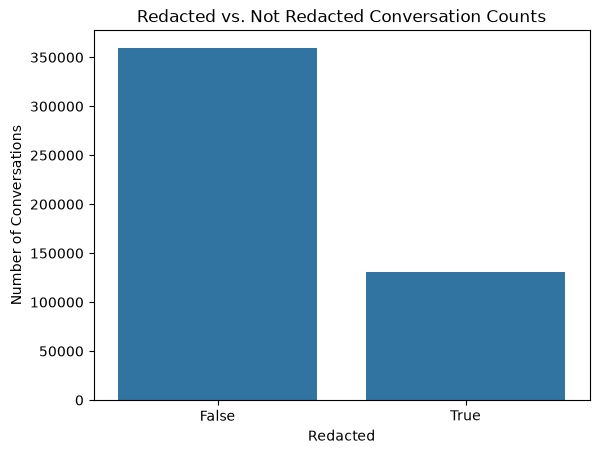

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(df, x="redacted")
plt.title("Redacted vs. Not Redacted Conversation Counts")
plt.xlabel("Redacted")
plt.ylabel("Number of Conversations")
plt.show()

Redacted conversations are not automatically unusable.

# language

Indicates the language of the conversation

In [6]:
df["language"].value_counts()

language
English       374394
Portuguese     21238
Spanish        14422
Russian        13860
unknown        12962
               ...  
Odia               1
Georgian           1
Tigrinya           1
Yiddish            1
Nepali             1
Name: count, Length: 152, dtype: int64

In [7]:
df["language"].value_counts(normalize=True)

language
English       0.762961
Portuguese    0.043280
Spanish       0.029390
Russian       0.028245
unknown       0.026415
                ...   
Odia          0.000002
Georgian      0.000002
Tigrinya      0.000002
Yiddish       0.000002
Nepali        0.000002
Name: proportion, Length: 152, dtype: float64

For this analysis, only enlglish conversations will be assessed. There are a few justifications for this:

1. It reduces the complexity and increases the practicality of the models.
2. Semantic differences between languages likely mean different results by language.
3. I only speak english and do not understand the other languages well enough to do feature engineering for them.

In [8]:
df_filtered = df[df["language"] == "English"]

# openai_moderation

In [9]:
df_filtered["openai_moderation"]

0         [{'categories': {'harassment': False, 'harassm...
1         [{'categories': {'harassment': False, 'harassm...
2         [{'categories': {'harassment': False, 'harassm...
3         [{'categories': {'harassment': False, 'harassm...
6         [{'categories': {'harassment': False, 'harassm...
                                ...                        
490705    [{'categories': {'harassment': False, 'harassm...
490706    [{'categories': {'harassment': False, 'harassm...
490707    [{'categories': {'harassment': False, 'harassm...
490709    [{'categories': {'harassment': False, 'harassm...
490710    [{'categories': {'harassment': False, 'harassm...
Name: openai_moderation, Length: 374394, dtype: object

In [10]:
df_filtered.iloc[0]["openai_moderation"]

array([{'categories': {'harassment': False, 'harassment/threatening': False, 'hate': False, 'hate/threatening': False, 'self-harm': False, 'self-harm/instructions': False, 'self-harm/intent': False, 'sexual': False, 'sexual/minors': False, 'violence': False, 'violence/graphic': False}, 'category_scores': {'harassment': 7.612839e-05, 'harassment/threatening': 9.07053e-06, 'hate': 3.7790054e-05, 'hate/threatening': 4.1802217e-08, 'self-harm': 2.6739393e-08, 'self-harm/instructions': 3.962927e-09, 'self-harm/intent': 5.7285128e-09, 'sexual': 9.927942e-06, 'sexual/minors': 4.4007415e-08, 'violence': 0.0005177184, 'violence/graphic': 1.00666746e-07}, 'flagged': False},
       {'categories': {'harassment': False, 'harassment/threatening': False, 'hate': False, 'hate/threatening': False, 'self-harm': False, 'self-harm/instructions': False, 'self-harm/intent': False, 'sexual': False, 'sexual/minors': False, 'violence': False, 'violence/graphic': False}, 'category_scores': {'harassment': 3.7922

Let's check how many conversations (including sub-conversations) are flagged

In [11]:
flagged_count = 0

for index, row in df_filtered.iterrows():
    for cat_dict in row["openai_moderation"]:
        if cat_dict["flagged"] == True:
            flagged_count +=1 

print(flagged_count)

48940


# turn

In [12]:
df_filtered["turn"].value_counts().to_dict()

{1: 246768,
 2: 51261,
 3: 26031,
 4: 15519,
 5: 9515,
 6: 6510,
 7: 4618,
 8: 3214,
 9: 2437,
 10: 1702,
 11: 1258,
 12: 1000,
 13: 792,
 14: 630,
 15: 484,
 16: 372,
 17: 316,
 18: 252,
 19: 244,
 20: 174,
 21: 153,
 23: 110,
 22: 109,
 24: 92,
 25: 86,
 26: 65,
 27: 63,
 50: 60,
 28: 51,
 29: 46,
 32: 34,
 30: 31,
 31: 30,
 33: 29,
 34: 26,
 36: 26,
 38: 23,
 35: 22,
 37: 21,
 39: 21,
 43: 18,
 44: 16,
 42: 14,
 41: 14,
 46: 12,
 40: 12,
 45: 11,
 48: 9,
 47: 8,
 55: 6,
 49: 5,
 63: 5,
 59: 4,
 51: 4,
 53: 4,
 52: 3,
 58: 3,
 60: 3,
 54: 3,
 56: 3,
 57: 3,
 77: 2,
 68: 2,
 86: 2,
 72: 2,
 69: 2,
 74: 2,
 85: 2,
 65: 1,
 120: 1,
 100: 1,
 64: 1,
 81: 1,
 93: 1,
 98: 1,
 166: 1,
 97: 1,
 158: 1,
 95: 1,
 67: 1,
 73: 1,
 76: 1,
 104: 1,
 215: 1,
 82: 1,
 134: 1,
 90: 1,
 114: 1,
 136: 1,
 61: 1,
 83: 1,
 142: 1,
 80: 1}

This responses the number of "turns" in the conversation, where a turn consists of the user response and LLM response

(array([3.67575e+05, 5.52200e+03, 8.06000e+02, 2.32000e+02, 1.19000e+02,
        9.30000e+01, 1.40000e+01, 1.00000e+01, 8.00000e+00, 5.00000e+00]),
 array([ 1. , 10.7, 20.4, 30.1, 39.8, 49.5, 59.2, 68.9, 78.6, 88.3, 98. ]),
 <BarContainer object of 10 artists>)

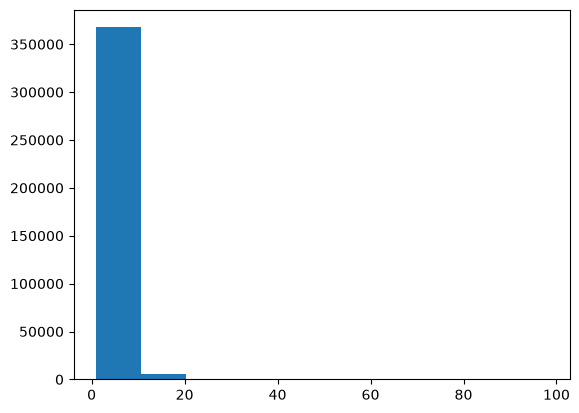

In [13]:
df_for_hist = df_filtered[df_filtered["turn"] < 100] # less than 100 just for a better idea of the spread

plt.hist(df_for_hist["turn"])

(array([298029.,  41550.,  16025.,   7832.,   2437.,   2960.,   1792.,
          1114.,    688.,    496.]),
 array([ 1. ,  2.8,  4.6,  6.4,  8.2, 10. , 11.8, 13.6, 15.4, 17.2, 19. ]),
 <BarContainer object of 10 artists>)

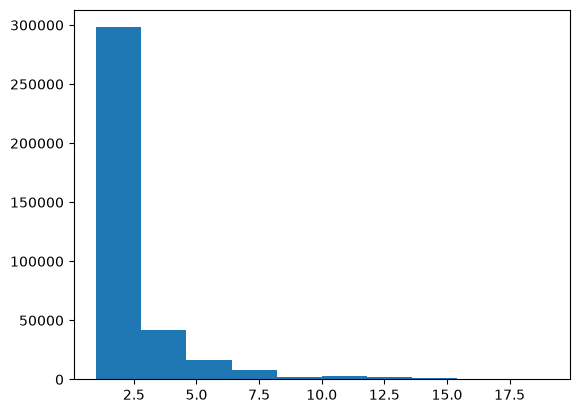

In [14]:
df_for_hist = df_filtered[df_filtered["turn"] < 20] # less than 20 just for a better idea of the spread

plt.hist(df_for_hist["turn"])

Overall, conversations are very short

# conversation

In [35]:
df_filtered.iloc[0]["conversation"]

array([{'content': "Beside OFAC's selective sanction that target the listed individiuals and entities, please elaborate on the other types of US's sanctions, for example, comprehensive and sectoral sanctions. Please be detailed as much as possible", 'role': 'user'},
       {'content': "The United States has a number of different types of sanctions that it can use to achieve its foreign policy goals, including both selective and comprehensive sanctions.\n\nSelective sanctions are targeted at specific individuals or entities that are believed to be engaged in activities that are contrary to US interests. These sanctions can take a variety of forms, including asset freezes, travel bans, and restrictions on financial transactions. The Office of Foreign Assets Control (OFAC) is the US government agency responsible for implementing and enforcing these types of sanctions.\n\nComprehensive sanctions, on the other hand, are more broadly based and aim to restrict entire sectors of a country's ec

This shows that a conversation contains both user input and assistant response. the 'role' flag for each dictionary in the list contains the marker for user or assistant. 

# Additional checks

Check for missing values

In [36]:
df_filtered.isna().sum().sum()

np.int64(0)

# Export filtered data (English only)

In [15]:
df_filtered.to_parquet("../data/processed/combined_filtered_english_only.parquet", index=False)